### 🤖 What are Multi-Agent RAG Systems?
A Multi-Agent RAG System splits the RAG pipeline into multiple specialized agents — each responsible for a specific role — and enables them to collaborate on a single query or task.

#### 1. 📋 Multi-Agent Network RAG System with LangGraph
Project Overview

A beginner-friendly Retrieval-Augmented Generation (RAG) system that uses a multi-agent architecture to intelligently answer questions from your documents. Built with LangGraph v0.3 for workflow orchestration and OpenAI for language understanding.

What It Does

Transforms your documents (PDFs, text files) into a searchable knowledge base that can answer questions intelligently using AI. Simply upload documents and ask questions in natural language - the system finds relevant information and generates comprehensive answers.
Key Features

- 📚 Multi-Format Support: Handles PDF and text documents
- 🤖 3-Agent Architecture: Specialized agents for document processing, retrieval, and answer generation
- 🔍 Smart Search: Vector-based semantic search finds relevant information
- 💬 Natural Language Q&A: Ask questions in plain English


In [ ]:
import os
from langchain.agents import create_agent
from typing import List, Literal
from pydantic import BaseModel, Field
from langchain_core.tools import tool
#from langchain_core.tools import Tool
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_astradb import AstraDBVectorStore
from langchain_groq import ChatGroq
from langchain_community.document_loaders import WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import END,START
from langgraph.graph import StateGraph
from typing import Annotated, TypedDict, Sequence
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage
from langgraph.graph.message import add_messages
from langchain_community.document_loaders import TextLoader
from pydantic import BaseModel
from typing import List
from langchain_core.documents import Document
from langchain_community.tools.tavily_search import TavilySearchResults

from langchain_ollama import ChatOllama


C:\Users\nihar\AppData\Local\Temp\ipykernel_25912\239226732.py:8: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import WikipediaQueryRun
USER_AGENT environment variable not set, consider setting it to identify your requests.


In [ ]:
import os
from dotenv import load_dotenv
load_dotenv()


os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

ASTRA_DB_API_ENDPOINT = ""
ASTRA_DB_APPLICATION_TOKEN = ""




embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

vector_store = AstraDBVectorStore(
    collection_name="internal_doc_blog",
    embedding=embeddings,
    api_endpoint=ASTRA_DB_API_ENDPOINT,
    token=ASTRA_DB_APPLICATION_TOKEN,
    namespace=None,
)


# llm = ChatGroq(
#     model="qwen/qwen3.8-27b",
#     max_tokens=200,
#     temperature=0
# )

llm = ChatOllama(
    model="qwen2.5:3b",
    base_url="http://localhost:11434"
)


c:\Users\nihar\AgenticAIWorkSpace\AgenticAI\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3936.70it/s]


In [3]:
tavily_tool = TavilySearchResults(max_results=2)
result = tavily_tool.invoke("recent advancements in Transformer architectures real-world applications optimization techniques production challenges")
result

C:\Users\nihar\AppData\Local\Temp\ipykernel_25912\2034461309.py:1: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily_tool = TavilySearchResults(max_results=2)


[{'title': 'Energy-Efficient Transformer Inference: Optimization Strategies for Time Series Classification',
  'url': 'https://arxiv.org/html/2502.16627v1',
  'content': 'Recent advancements in transformer architectures have significantly advanced time series analysis across various domains, including healthcare, finance, and predictive maintenance, enabling more accurate forecasting, anomaly detection, and decision-making processes . The ability of AI models to process sequential data efficiently has enabled substantial improvements in these fields, allowing for more accurate forecasting, anomaly detection, and decision-making processes . At the core of these developments are transformer-based architectures, which have demonstrated superior performance over traditional models, such as recurrent neural networks (RNNs) and long short-term memory (LSTM) networks, by leveraging self-attention mechanisms to capture long-range dependencies in temporal data . [...] A significant challenge in

In [4]:
# -------------------------------
# 1. Prepare Vectorstore
# -------------------------------
# docs = TextLoader("search_internal_doc_blog.txt",encoding="utf-8").load()
# splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
# chunks = splitter.split_documents(docs)
#vector_store.add_documents(documents=chunks)
retriever = vector_store.as_retriever(
)


In [5]:
class BlogState(TypedDict):
    topic: str
    research: str
    blog: str

In [6]:
@tool
def search_internal_documents(query: str) -> str:
    """
    Search the internal AstraDB vector database for relevant
    information about Transformers, attention mechanisms,
    encoder-decoder architectures, and technical research.

    Use this tool when:
    - The user asks about internal research documents.
    - Information is available in the internal knowledge base.
    - Technical explanations are needed from stored documents.
    - Research findings should be grounded in internal sources.

    Args:
        query: A specific semantic search query.

    Returns:
        Relevant document passages with source metadata.
    """

    print(f"Internal RAG Search: {query}")

    docs = retriever.invoke(query)

    if not docs:
        return "No relevant internal documents found."

    results = []

    for index, doc in enumerate(docs, start=1):

        source = doc.metadata.get("source", "Unknown")

        results.append(
            f"""
            Document {index}
            Source: {source}
            Content:
            {doc.page_content}
            """
        )

    print("result from search_internal_documents")
    results  

    return "\n\n".join(results)



In [7]:
@tool
def search_web(query: str) -> str:
    """Search the web using Tavily and return only the
    relevant text content from the top 2 results."""

    response = tavily_tool.invoke({"query": query})

    if isinstance(response, dict):
        results = response.get("results", [])
    else:
        results = response

    contents = [
        item["content"]
        for item in results[:2]
        if item.get("content")
    ]

    print("result from contents we search")
    contents

    return "\n\n".join(contents) if contents else "No results found."

In [8]:
# ==========================================
# 2. Create Research Agent
# ==========================================

research_agent = create_agent(
    model=llm,
    tools=[search_internal_documents, search_web],
    system_prompt="""
    You are a professional research agent.

    Responsibilities:
    - Research the user's topic thoroughly.
    - Search internal research documents when relevant.
    - Use Tavily to gather external information.
    - Verify important factual claims where possible.
    - Preserve source URLs and document references.
    - Clearly identify uncertainty or missing evidence.
    - Never fabricate facts or citations.

    Return organized research notes containing:
    1. Topic overview
    2. Key findings
    3. Technical details
    4. Real-world examples
    5. Sources and references

    Do not write the final blog.
    """
)


# ==========================================
# 3. Create Blog Writer Agent
# ==========================================

blog_agent = create_agent(
    model=llm,
    tools=[],
    system_prompt="""
    You are a professional technical blog writer.

    Responsibilities:
    - Write a detailed, engaging technical blog.
    - Use the research provided by the research agent.
    - Explain complex concepts clearly.
    - Maintain technical accuracy.
    - Do not invent sources or unsupported claims.

    Blog structure:
    1. SEO-friendly title
    2. Introduction
    3. Main technical sections
    4. Practical examples
    5. Benefits and limitations
    6. Conclusion
    7. References

    Return the final blog in Markdown.
    """
)


In [9]:
from langchain_core.messages import HumanMessage, AIMessage, ToolMessage

def research_node(state: BlogState) -> dict:

    print("\n========== RESEARCH AGENT STARTED ==========")

    result = research_agent.invoke({
        "messages": [
            HumanMessage(
                content=f"""
                Research the following topic thoroughly:
                {state['topic']}

                Use available research tools.
                """
            )
        ]
    })

    for message in result["messages"]:

        # 1. Print tools requested by the LLM
        if isinstance(message, AIMessage) and message.tool_calls:

            for tool_call in message.tool_calls:
                print("\n========== TOOL CALLED ==========")
                print("Tool Name:", tool_call["name"])
                print("Tool Arguments:", tool_call["args"])

        # 2. Print the actual tool result
        elif isinstance(message, ToolMessage):

            print("\n========== TOOL RESULT ==========")
            print("Tool Name:", message.name)
            print("Tool Output:")
            print(message.content)

        # 3. Print LLM responses
        elif isinstance(message, AIMessage) and message.content:

            print("\n========== RESEARCH LLM RESPONSE ==========")
            print(message.content)

    research = result["messages"][-1].content

    print("\n========== RESEARCH PASSED TO BLOG WRITER ==========")
    print(research)

    return {"research": research}

In [10]:
def blog_node(state: BlogState) -> dict:

    print("\n========== BLOG WRITER STARTED ==========")

    prompt = f"""
    Write a detailed technical blog.

    Topic:
    {state['topic']}

    Research Findings:
    {state['research']}

    Use provided research and preserve source references.
    """

    print("\n========== INPUT PASSED TO BLOG LLM ==========")
    print(prompt)

    result = blog_agent.invoke({
        "messages": [
            HumanMessage(content=prompt)
        ]
    })

    blog = result["messages"][-1].content

    return {"blog": blog}

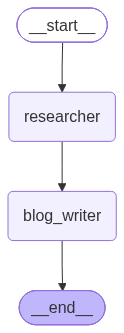

In [11]:
# ==================================================
# STEP 7: BUILD LANGGRAPH
# ==================================================

builder = StateGraph(BlogState)

builder.add_node("researcher", research_node)
builder.add_node("blog_writer", blog_node)

builder.add_edge(START, "researcher")
builder.add_edge("researcher", "blog_writer")
builder.add_edge("blog_writer", END)

graph = builder.compile()
graph

In [12]:
response = graph.invoke({
    "topic": "Write a detailed technical blog on Transformer architectures and their variants in production deployments. Use both internal FAISS documents and Tavily web search."
})

print("\n========== FINAL BLOG ==========")
print(response["blog"])


========== RESEARCH AGENT STARTED ==========
Internal RAG Search: Transformer architectures and their variants in production deployments
result from contents we search
result from search_internal_documents

========== TOOL CALLED ==========
Tool Name: search_web
Tool Arguments: {'query': 'Transformer architectures and their variants in production deployments'}

========== TOOL CALLED ==========
Tool Name: search_internal_documents
Tool Arguments: {'query': 'Transformer architectures and their variants in production deployments'}

========== TOOL RESULT ==========
Tool Name: search_web
Tool Output:
Key Takeaways
 What is a Transformer Architecture and Why Does it Matter for AI?
  + The Shift from Recurrent Neural Networks
  + Key Advantages in Modern AI
 Understanding the Self-Attention Mechanism
  + Multi-Head Attention
 How Transformers Power Large Language Models
  + Architecture Variations
 Deploying Transformer-Based Systems in Production
  + Leveraging Pre-trained Transformers
  